In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix,
)

In [ ]:
data = load_iris()

In [ ]:
x=data.data
y=data.target

In [ ]:
x.shape

(150, 4)

In [ ]:
y.shape

(150,)

In [ ]:
print(data.target_names)

['setosa' 'versicolor' 'virginica']


In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=42)

In [ ]:
#testing with diff values of k-
k_values = range(1,16)
accuracies = []

for k in k_values:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(x_train,y_train)
  y_pred = knn.predict(x_test)
  accuracy = accuracy_score(y_test,y_pred)
  accuracies.append(accuracy)

In [ ]:
# training with the best model
best_k =k_values[np.argmax(accuracies)]
best_model = KNeighborsClassifier(n_neighbors=best_k)
best_model.fit(x_train,y_train)
y_pred=best_model.predict(x_test)


In [ ]:
confusion_matrix(y_test,y_pred)

array([[19,  0,  0],
       [ 0, 13,  0],
       [ 0,  0, 13]])

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



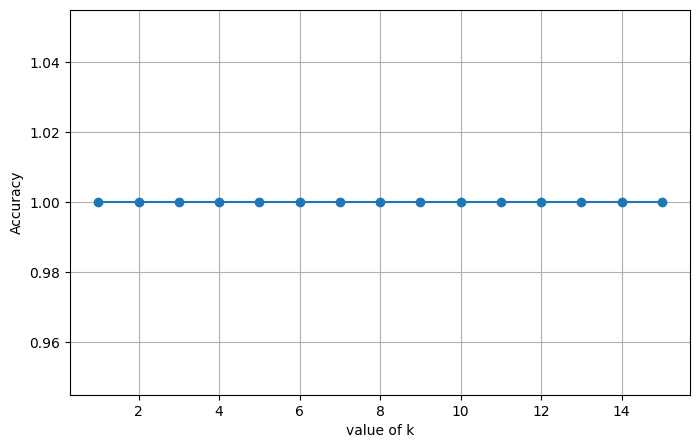

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(k_values,accuracies,marker='o')
plt.xlabel("value of k")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()